In [3]:
from tensorflow import keras
from tensorflow.keras.datasets import reuters
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [4]:
(x_train, y_train), (x_test, y_test) = reuters.load_data()

In [5]:
x_train.shape, x_test.shape

((8982,), (2246,))

In [6]:
np.unique(y_train, return_counts = True)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45], dtype=int64),
 array([  55,  432,   74, 3159, 1949,   17,   48,   16,  139,  101,  124,
         390,   49,  172,   26,   20,  444,   39,   66,  549,  269,  100,
          15,   41,   62,   92,   24,   15,   48,   19,   45,   39,   32,
          11,   50,   10,   49,   19,   19,   24,   36,   30,   13,   21,
          12,   18], dtype=int64))

- 로이터 뉴스 카테고리 분류 데이터
    - 총 11258개의 뉴스 기사 데이터
    - 총 46개의 카테고리 분류
    - 예)
        - 중부 지방은 대체로 맑겠으나, 남부 지방은 구름이 많겠습니다 -> 날씨
        - 올 초부터 유동성의 힘으로 주가가 일정하게 상승했습니다 -> 주식

In [7]:
word_index = reuters.get_word_index()

In [8]:
word_index

{'mdbl': 10996,
 'fawc': 16260,
 'degussa': 12089,
 'woods': 8803,
 'hanging': 13796,
 'localized': 20672,
 'sation': 20673,
 'chanthaburi': 20675,
 'refunding': 10997,
 'hermann': 8804,
 'passsengers': 20676,
 'stipulate': 20677,
 'heublein': 8352,
 'screaming': 20713,
 'tcby': 16261,
 'four': 185,
 'grains': 1642,
 'broiler': 20680,
 'wooden': 12090,
 'wednesday': 1220,
 'highveld': 13797,
 'duffour': 7593,
 '0053': 20681,
 'elections': 3914,
 '270': 2563,
 '271': 3551,
 '272': 5113,
 '273': 3552,
 '274': 3400,
 'rudman': 7975,
 '276': 3401,
 '277': 3478,
 '278': 3632,
 '279': 4309,
 'dormancy': 9381,
 'errors': 7247,
 'deferred': 3086,
 'sptnd': 20683,
 'cooking': 8805,
 'stratabit': 20684,
 'designing': 16262,
 'metalurgicos': 20685,
 'databank': 13798,
 '300er': 20686,
 'shocks': 20687,
 'nawg': 7972,
 'tnta': 20688,
 'perforations': 20689,
 'affiliates': 2891,
 '27p': 20690,
 'ching': 16263,
 'china': 595,
 'wagyu': 16264,
 'affiliated': 3189,
 'chino': 16265,
 'chinh': 16266,
 '

In [9]:
idx2word = {0 : "<PAD>", 1 : "<s>", 2 : "<UNK>"}

In [10]:
idx2word.update({value + 3 : key for key, value in word_index.items()})

In [11]:
print(x_train[0])

[1, 27595, 28842, 8, 43, 10, 447, 5, 25, 207, 270, 5, 3095, 111, 16, 369, 186, 90, 67, 7, 89, 5, 19, 102, 6, 19, 124, 15, 90, 67, 84, 22, 482, 26, 7, 48, 4, 49, 8, 864, 39, 209, 154, 6, 151, 6, 83, 11, 15, 22, 155, 11, 15, 7, 48, 9, 4579, 1005, 504, 6, 258, 6, 272, 11, 15, 22, 134, 44, 11, 15, 16, 8, 197, 1245, 90, 67, 52, 29, 209, 30, 32, 132, 6, 109, 15, 17, 12]


In [12]:
" ".join(map(lambda x: idx2word[x], x_train[0]))

'<s> mcgrath rentcorp said as a result of its december acquisition of space co it expects earnings per share in 1987 of 1 15 to 1 30 dlrs per share up from 70 cts in 1986 the company said pretax net should rise to nine to 10 mln dlrs from six mln dlrs in 1986 and rental operation revenues to 19 to 22 mln dlrs from 12 5 mln dlrs it said cash flow per share this year should be 2 50 to three dlrs reuter 3'

In [13]:
len(word_index.keys())

30979

# 사용할 단어 수 테스트

In [20]:
(x_train, y_train), (x_test, y_test) = reuters.load_data(num_words = 1000)
idx2word = {0 : "<PAD>", 1 : "<s>", 2 : "<UNK>"}
idx2word.update({value + 3 : key for key, value in word_index.items()})

In [22]:
" ".join(map(lambda x: idx2word[x], x_train[1]))

'<s> <UNK> de <UNK> <UNK> lt <UNK> <UNK> and lt <UNK> <UNK> corp of <UNK> have each taken 50 pct <UNK> in <UNK> company <UNK> <UNK> <UNK> <UNK> de <UNK> said in a statement it gave no financial details of the transaction <UNK> <UNK> <UNK> turnover in 1986 was 17 5 billion <UNK> francs reuter 3'

# 문장의 길이 분석

In [23]:
lengths = np.array([len(x) for x in x_train])

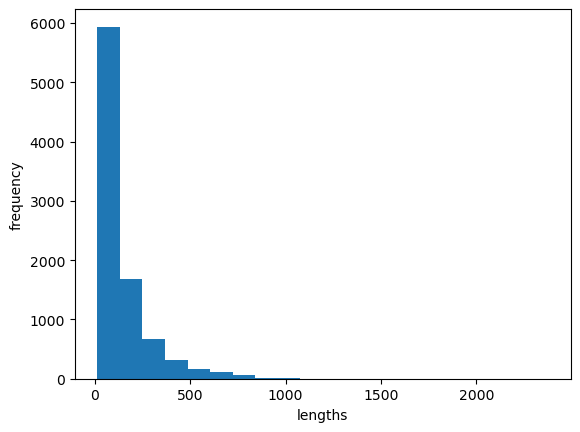

In [25]:
plt.figure()

plt.hist(lengths, bins = 20)

plt.xlabel("lengths")
plt.ylabel("frequency")
plt.show()

In [26]:
np.mean(lengths), np.min(lengths), np.max(lengths)

(145.5398574927633, 13, 2376)

In [27]:
np.quantile(lengths, [0.25, 0.5, 0.75])

array([ 60.,  95., 179.])

In [28]:
# 종속변수 종류 수 확인
len(np.unique(y_train))

46

# 데이터 분할

In [29]:
x_sub, x_val, y_sub, y_val = train_test_split(x_train, y_train, test_size = 0.2,
                                              stratify = y_train, random_state = 26)

In [31]:
x_sub.shape, x_val.shape, x_test.shape

((7185,), (1797,), (2246,))

In [32]:
sub_seq = pad_sequences(x_sub, maxlen = 150, truncating = "post")
val_seq = pad_sequences(x_val, maxlen = 150, truncating = "post")
test_seq = pad_sequences(x_test, maxlen = 150, truncating = "post")

# 모델 설계

In [35]:
model = keras.Sequential()
model.add(keras.Input(shape = (150,)))

model.add(keras.layers.Embedding(1000, 128))
model.add(keras.layers.Dropout(0.2))

model.add(keras.layers.Conv1D(64, 5))
model.add(keras.layers.BatchNormalization())
model.add(keras.layers.Activation(keras.activations.relu))
model.add(keras.layers.MaxPool1D(4))

model.add(keras.layers.LSTM(128, dropout = 0.2))
model.add(keras.layers.Dropout(0.2))

model.add(keras.layers.Dense(46, activation = "softmax"))

In [36]:
model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])
es_cb = keras.callbacks.EarlyStopping(patience = 4, restore_best_weights = True)

In [37]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ (None, 150, 128)            │         128,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 150, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 146, 64)             │          41,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 146, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 146, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_2 (MaxPooling1D)       │ (None, 36, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 128)                 │          98,816 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 46)                  │           5,934 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 274,030 (1.05 MB)

 Trainable params: 273,902 (1.04 MB)

 Non-trainable params: 128 (512.00 B)

In [38]:
history = model.fit(sub_seq, y_sub, epochs = 100, batch_size = 32,
                    validation_data = (val_seq, y_val), callbacks = [es_cb])

Epoch 1/100
225/225 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.4291 - loss: 2.2860 - val_accuracy: 0.3161 - val_loss: 2.7827
Epoch 2/100
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.6129 - loss: 1.5726 - val_accuracy: 0.6828 - val_loss: 1.3369
Epoch 3/100
225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - accuracy: 0.6813 - loss: 1.3194 - val_accuracy: 0.7117 - val_loss: 1.1800
Epoch 4/100
225/225 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.7160 - loss: 1.1460 - val_accuracy: 0.7474 - val_loss: 1.0578
Epoch 5/100
225/225 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.7413 - loss: 1.0404 - val_accuracy: 0.7696 - val_loss: 1.0015
Epoch 6/100
225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.7713 - loss: 0.9342 - val_accuracy: 0.7841 - val_loss: 0.9274
Epoch 7/100
225/225 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step - accuracy: 0.7876 - loss: 0.8458 - val_accuracy: 0.7863 - val_loss: 0.9016
Epoch 8/100
225/225 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - accuracy: 0.8118 - loss: 0.7798 -

In [39]:
model.evaluate(test_seq, y_test)

71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8100 - loss: 0.8185 


[0.851115882396698, 0.800979495048523]